# Handwritten Digit Classification using CNN




## Import Libraries

In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from keras.models import Sequential
from keras.layers import Dense, Conv2D, MaxPooling2D, BatchNormalization, Dropout, Flatten
from keras.utils import to_categorical

## Load Dataset

In [68]:
A = pd.read_csv("/content/digitsnpixels.csv")
A.head(11)

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## Dataset Shape

In [69]:
A.shape

(42000, 785)

## Visualize a Single Image

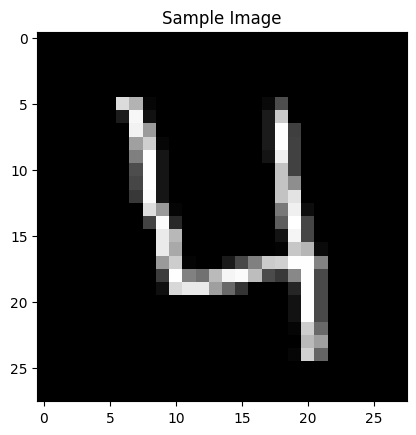

In [71]:
w1 = A[3:4].drop(labels="label", axis=1).values.reshape(28,28)
plt.imshow(w1, cmap='gray')
plt.title("Sample Image")
plt.show()

## Visualize Multiple Images

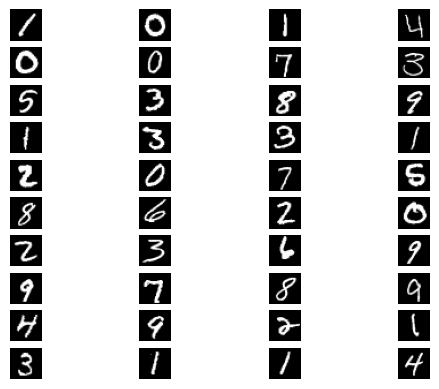

In [73]:
q = 1

for i in range(40):
    plt.subplot(10,4,q)
    x = A[i:i+1].drop(labels="label", axis=1).values.reshape(28,28)
    plt.imshow(x, cmap='gray')
    plt.axis('off')
    q += 1

plt.show()

## Prepare Target Variable (Y)

In [74]:
Y = to_categorical(A["label"])   #onenhot encoding
Y.shape

(42000, 10)

## Prepare Input Features (X)

In [75]:
X = A.iloc[:,1:] / 255  # Normalize
X = X.values
X.shape

(42000, 784)

## Reshape for CNN (Important Step)

In [78]:
X = X.reshape(42000, 28, 28, 1)



## Build CNN Model

In [79]:
nn = Sequential()

# First Conv Block
nn.add(Conv2D(filters=16, kernel_size=(3,3), padding='same',
              input_shape=(28,28,1)))  # 1 represents grayscale channel

# 1.Filters
# Small matrix of learnable weights (e.g. 3×3). Each filter detects ONE specific feature (edge, curve, color gradient).

# 2. Feature Map
# Output of applying a filter across the full input. If we use 16 filters, we get 16 feature maps stacked together.

# 3. Stride
# How many pixels the filter moves each step.

# 4. Padding
# Zeros added around the input border before convolution.
# Padding types
# i. Valid padding:- No padding. Output shrinks after each conv.
# ii. Same  padding :- Output same spatial size as input. Most common.


nn.add(MaxPooling2D(pool_size=(2,2)))


# Pooling types
# 1.Max pooling (most common)
# Takes the maximum value from each pooling window
# Most common. Captures strongest activations (dominant features).


# 2. Avg pooling
# Takes the average of values in each pooling window
# Smoother. Good for background/texture features.


nn.add(BatchNormalization())
# Each layer receives inputs with different distributions as weights change.
# Batch Norm normalizes activations to have μ(mean)≈0, σ(std)≈1.

nn.add(Dropout(0.3))

# Second Conv Block
nn.add(Conv2D(filters=16, kernel_size=(3,3),
               padding='same'))

nn.add(MaxPooling2D(pool_size=(2,2)))
nn.add(BatchNormalization())
nn.add(Dropout(0.3))


# Fully Connected Layers
nn.add(Flatten())
nn.add(Dense(128, activation='relu'))
nn.add(Dense(128, activation='relu'))
nn.add(Dense(10, activation='softmax'))

nn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])




/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## Train Model

In [80]:
history = nn.fit(X, Y, batch_size=64, epochs=2, validation_split=0.2)

Epoch 1/2
525/525 ━━━━━━━━━━━━━━━━━━━━ 30s 48ms/step - accuracy: 0.9022 - loss: 0.3033 - val_accuracy: 0.9544 - val_loss: 0.1481
Epoch 2/2
525/525 ━━━━━━━━━━━━━━━━━━━━ 26s 50ms/step - accuracy: 0.9622 - loss: 0.1168 - val_accuracy: 0.9789 - val_loss: 0.0655


## Make Prediction

In [85]:
sample = A[933:934].drop(labels="label", axis=1).values.reshape(1,28,28,1)
prediction = nn.predict(sample)

print("Prediction Probabilities:")
print(prediction)

print("Predicted Digit:", np.argmax(prediction))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step
Prediction Probabilities:
[[1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]
Predicted Digit: 0


## Visualize Predicted Image

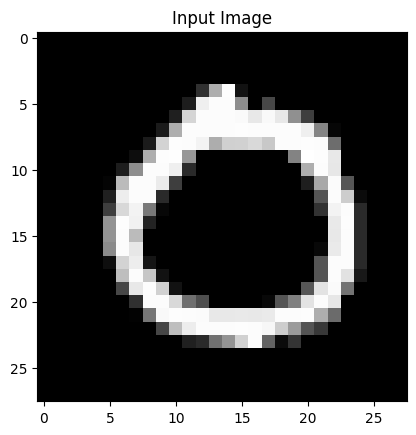

In [86]:
img = A[933:934].drop(labels="label", axis=1).values.reshape(28,28)
plt.imshow(img, cmap='gray')
plt.title("Input Image")
plt.show()